# Análisis de Tests de Perlin Noise

Este notebook combina los tests de uniformidad, avalancha y patrones para el generador de hashes usado en el ruido Perlin.
> **ADVERTENCIA:** La ejecución de estos tests es un proceso intensivo que requiere de un tiempo considerable. Como referencia, en un procesador Ryzen 7 5700X utilizando todos los hilos, la ejecución tomó más de 2 horas.

## 0. Compilación de los tests, variables e imports

In [811]:
import re
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import numpy as np
from scipy.stats import chi2, binom

In [812]:
FIGSIZE            = (16, 7.5)
TITLE_FONT_SIZE    = 24
SUBTITLE_FONT_SIZE = 20
LEGEND_FONT_SIZE   = 18
LABEL_FONT_SIZE    = 16
TICK_FONT_SIZE     = 16

COLOR_BLUE         = '#1B4182'
COLOR_LIGHT_GREEN  = '#90BE6D'
COLOR_GREEN        = "#2FAE53"
COLOR_YELLOW       = '#F9C74F'
COLOR_ORANGE       = '#F9844A'
COLOR_RED          = '#C0392B'
COLOR_PURPLE       = '#9B59B6'

GRAY_DARK          = '#6E6E6E'
GRAY               = '#C0C0C0'
GRAY_LIGHT         = '#D0D0D0'
GRAY_LIGHTER       = '#E0E0E0'


plt.rc('font',   size=LABEL_FONT_SIZE)
plt.rc('axes',   titlesize=TITLE_FONT_SIZE, labelsize=LABEL_FONT_SIZE)
plt.rc('xtick',  labelsize=TICK_FONT_SIZE)
plt.rc('ytick',  labelsize=TICK_FONT_SIZE)
plt.rc('legend', fontsize=LEGEND_FONT_SIZE)
plt.rc('figure', titlesize=TITLE_FONT_SIZE)

Precompilamos todos los test

In [813]:
print("Compilando uniformity_test...")
cmd = ["zig", "build", "--release=fast"]
subprocess.run(cmd, check=True)
print(' '.join(cmd))

Compilando uniformity_test...
zig build --release=fast


Función hash a testear. Opciones disponibles `[ custom_v1 | custom_v2 | rapidhash ]`

In [814]:
HASH_FUNCTION = "custom_v1"

## 1. Test de Uniformidad

Analiza si la distribución de valores generados por el hash es uniforme.

### 1.1 Extracción de Datos

Compilación y ejecución del test C para obtención de métricas (frecuencias, entropía, Chi-cuadrado).

In [799]:
uniformity_output_file = Path("logs/uniformity_output_64b.txt")
uniformity_output_file.parent.mkdir(parents=True, exist_ok=True)

UNIFORMITY_SAMPLES = 10_000_000_000
LOG_START_INDEX = 100
LOG_FACTOR = 100 ** (1/100)
SEED = 0xDEADBEEFCAFEBABE

print("\nEjecutando test...")
cmd = ["./zig-out/bin/uniformity_64b", str(UNIFORMITY_SAMPLES), str(LOG_START_INDEX), str(LOG_FACTOR), str(SEED), HASH_FUNCTION]
print(' '.join(cmd))

result = subprocess.run(cmd, text=True, check=True, capture_output=True)
data_uniformity = result.stdout
uniformity_output_file.write_text(data_uniformity)


Ejecutando test...
./zig-out/bin/uniformity_64b 10000000000 100 1.0471285480508996 16045690984503098046 custom_v1


29903

#### 1.1.1 Datos en bruto obtenidos

In [800]:
data_uniformity.strip().splitlines()[:5]

['{000000000000100, 65436.00, 65436.00, 65436.00, 65436.00, 6.64385619}',
 '{000000000000104, 65432.00, 65432.00, 65432.00, 65432.00, 6.70043972}',
 '{000000000000108, 65428.00, 65428.00, 65428.00, 65428.00, 6.75488750}',
 '{000000000000113, 65423.00, 65423.00, 65423.00, 65423.00, 6.82017896}',
 '{000000000000118, 65418.00, 65418.00, 65418.00, 65418.00, 6.88264305}']

In [801]:
data_uniformity.strip().splitlines()[-32:-27]

['{000004082218201, 65242.24, 65638.16, 65533.92, 65509.14, 15.99998843}',
 '{000004274607217, 65124.66, 65539.37, 65425.56, 65448.26, 15.99998897}',
 '{000004476063248, 65326.80, 65594.69, 65535.23, 65588.75, 15.99998944}',
 '{000004687013609, 65430.58, 65369.43, 65534.03, 65631.89, 15.99998992}',
 '{000004907905755, 65607.83, 65228.64, 65461.90, 65617.12, 15.99999038}']

### 1.2 Refinado de Datos

Procesamiento de salida textual a estructuras numéricas ($f_{abs}$, $\chi^2$, $H$).

In [802]:
frequencies_regex = re.compile(r'(\d+): (\d+)')
frequency_matches = frequencies_regex.findall(data_uniformity)

# Formato: {Total, Chi2_W0, Chi2_W1, Chi2_W2, Chi2_W3, AvgEntropy}
metrics_log_regex = re.compile(r'\{(\d+), ([\d.]+), ([\d.]+), ([\d.]+), ([\d.]+), ([\d.]+)\}')
metrics_matches = metrics_log_regex.findall(data_uniformity)

f_abs = [int(value) for _, value in frequency_matches]

chi2_log = [(int(idx), [float(c0), float(c1), float(c2), float(c3)]) 
            for idx, c0, c1, c2, c3, _ in metrics_matches]

entropy_log = [(int(idx), float(ent)) for idx, _, _, _, _, ent in metrics_matches]

### 1.3 Visualización de Datos

#### 1.3.1 Distribución de Frecuencias y Desviaciones ($\delta_{rel}$)

Desviación relativa porcentual por valor de salida (0-255).

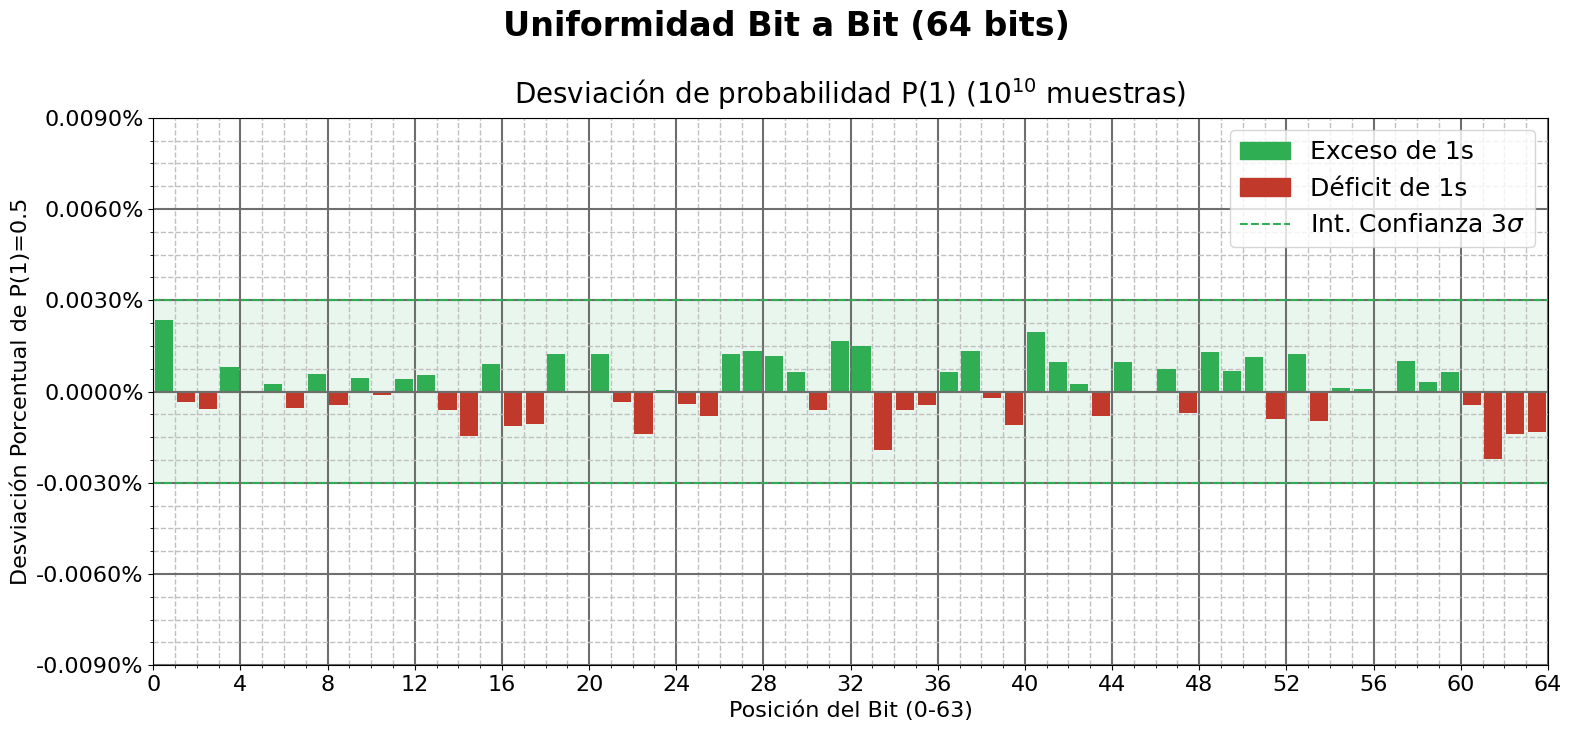

In [803]:
N = chi2_log[-1][0]
f_exp = N / 2.0
delta_rel = [(f - f_exp) / f_exp * 100 for f in f_abs]

bar_centers = [i + 0.5 for i in range(len(f_abs))]
sigma_3_pct = 300.0 / np.sqrt(N)
y_limit = 3 * sigma_3_pct

fig, ax = plt.subplots(figsize=FIGSIZE)

# 1. Ejes
ax.set_xlim(0, 64)
ax.set_ylim(-y_limit, y_limit)
ax.set_xlabel('Posición del Bit (0-63)')
ax.set_ylabel('Desviación Porcentual de P(1)=0.5')

# 2. Ticks
ax.set_xticks(range(0, 65, 4))
ax.set_xticklabels([f'{x}' for x in range(0, 65, 4)])

yticks = np.linspace(-y_limit, y_limit, 7)
ax.set_yticks(yticks)
ax.set_yticklabels([f'{y:.4f}%' for y in yticks])

ax.minorticks_on()
ax.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax.xaxis.set_minor_formatter(plt.NullFormatter())

# 3. Rejilla
ax.grid(which='major', axis='both', linestyle='-', color=GRAY_DARK, linewidth=1.5)
ax.grid(which='minor', axis='both', linestyle='--', color=GRAY, linewidth=1)

# 4. Títulos
fig.suptitle('Uniformidad Bit a Bit (64 bits)', fontweight='bold')
ax.set_title(f'Desviación de probabilidad P(1) (${10}^{{{np.log10(N):.0f}}}$ muestras)',
             fontsize=SUBTITLE_FONT_SIZE, pad=10)

# 5. Elementos principales
bar_colors = [COLOR_GREEN if d > 0 else COLOR_RED for d in delta_rel]
ax.bar(bar_centers, delta_rel, color=bar_colors, width=5/6, zorder=2)
ax.axhline(y=0, color=GRAY_DARK, linestyle='-', linewidth=1.5)

ax.axhline(y=sigma_3_pct, color=COLOR_GREEN, linestyle='--', linewidth=1.5)
ax.axhline(y=-sigma_3_pct, color=COLOR_GREEN, linestyle='--', linewidth=1.5)
ax.fill_between([-1, 64], -sigma_3_pct, sigma_3_pct, color=COLOR_GREEN, alpha=0.1)

positive_patch = mpatches.Patch(color=COLOR_GREEN, label='Exceso de 1s')
negative_patch = mpatches.Patch(color=COLOR_RED, label='Déficit de 1s')
confidence_line = plt.Line2D([0], [0], color=COLOR_GREEN, linestyle='--',
                             label='Int. Confianza 3$\\sigma$')
ax.legend(handles=[positive_patch, negative_patch, confidence_line], loc='upper right')

plt.tight_layout()
plt.show()

#### 1.3.2 Convergencia del Test Chi-Cuadrado ($\chi^2$)

Evolución de $\chi^2$ respecto al número de muestras $N$. Bandas de confianza para distribución uniforme.

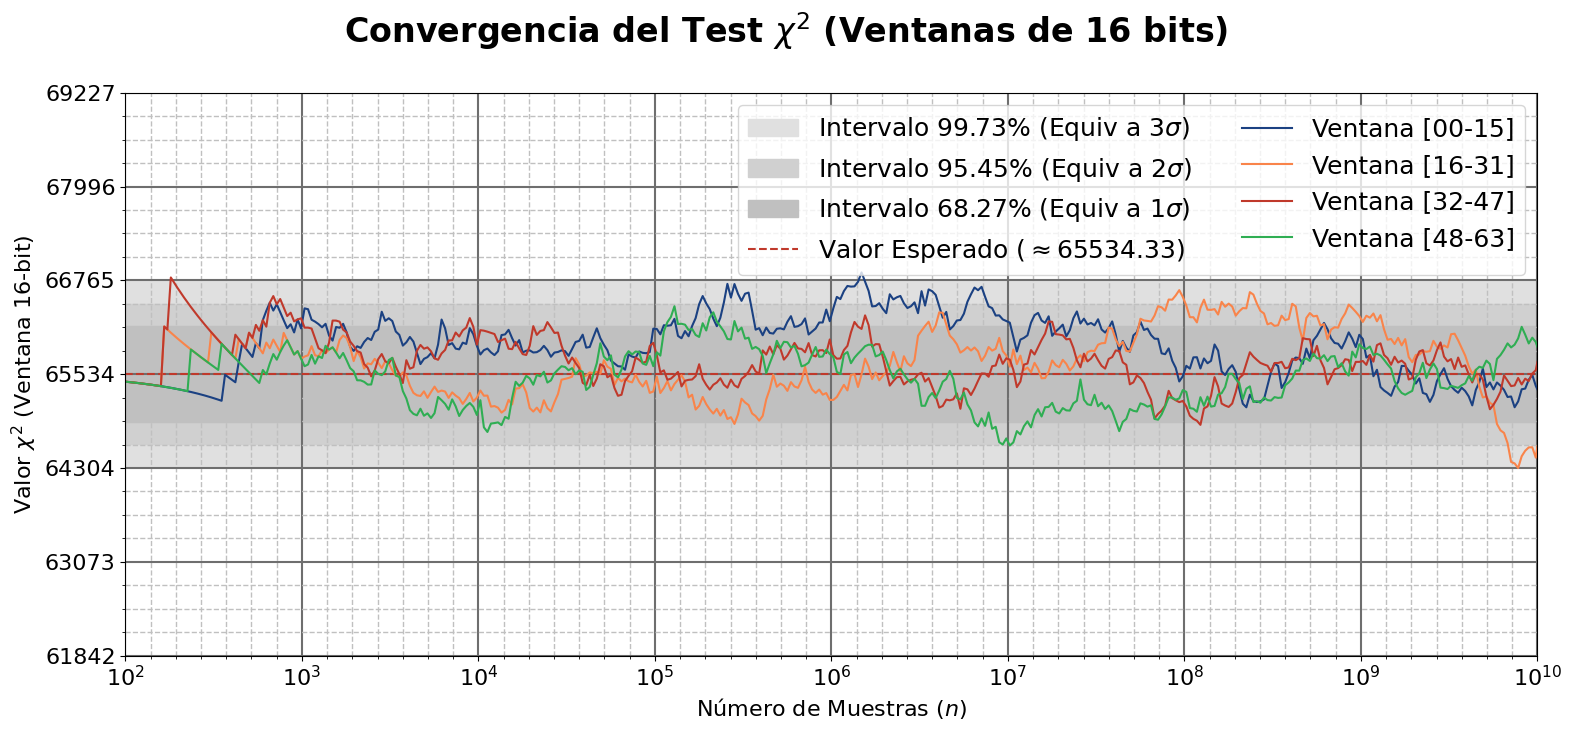

In [804]:
n_points = [x for x, _ in chi2_log]
chi2_values = np.array([vals for _, vals in chi2_log])

degrees_of_freedom = 2**16 - 1

thresholds = [
    (0.0027, GRAY_LIGHTER, '99.73% (Equiv a 3$\\sigma$)'),
    (0.0455, GRAY_LIGHT,   '95.45% (Equiv a 2$\\sigma$)'),
    (0.3173, GRAY,         '68.27% (Equiv a 1$\\sigma$)'),
]

fig, ax = plt.subplots(figsize=FIGSIZE)

# 1. Ejes
ax.set_xscale('log', base=10)
ax.set_xlim(n_points[0], n_points[-1])

y_avg = chi2.ppf(0.5, degrees_of_freedom)
p_low_3s = thresholds[0][0] / 8
val_low_3s = chi2.ppf(p_low_3s, degrees_of_freedom)
val_high_3s = chi2.ppf(1 - p_low_3s, degrees_of_freedom)

margin_3s = (val_high_3s - val_low_3s) / 2.0
y_limit = margin_3s * 3.0

y_min = y_avg - y_limit
y_max = y_avg + y_limit

ax.set_ylim(y_min, y_max)
ax.set_xlabel('Número de Muestras ($n$)')
ax.set_ylabel('Valor $\\chi^2$ (Ventana 16-bit)')

# 2. Ticks
min_pow = int(np.floor(np.log10(n_points[0])))
max_pow = int(np.ceil(np.log10(n_points[-1])))
pow_range = range(min_pow, max_pow + 1)

ax.set_xticks([10**i for i in pow_range])
ax.set_xticklabels([fr'$10^{{{i}}}$' for i in pow_range])

ax.minorticks_on()
ax.xaxis.set_minor_locator(plt.FixedLocator([10**(min_pow + i/7) for i in range((max_pow - min_pow) * 7)]))
ax.xaxis.set_minor_formatter(plt.NullFormatter())

yticks = np.linspace(y_min, y_max, 7)
ax.set_yticks(yticks)
ax.set_yticklabels([f'{y:.0f}' for y in yticks])

# 3. Rejilla
ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

# 4. Títulos
fig.suptitle('Convergencia del Test $\\chi^2$ (Ventanas de 16 bits)', fontweight='bold')

# 5. Elementos principales
for alpha, color, label in thresholds:
    p_low = alpha / 8
    val_low = chi2.ppf(p_low, degrees_of_freedom)
    val_high = chi2.ppf(1 - p_low, degrees_of_freedom)
    ax.fill_between(n_points, val_low, val_high, color=color, label=f'Intervalo {label}')

ax.axhline(y_avg, color=COLOR_RED, linestyle='--', linewidth=1.5,
           label=f'Valor Esperado ($\\approx${y_avg:.2f})')

window_labels = ['Ventana [00-15]', 'Ventana [16-31]', 'Ventana [32-47]', 'Ventana [48-63]']

colors = [COLOR_BLUE, COLOR_ORANGE, COLOR_RED, COLOR_GREEN]
for i in range(4):
    ax.plot(n_points, chi2_values[:, i], label=window_labels[i], color=colors[i], linewidth=1.5)

ax.legend(loc='upper right', ncol=2)

plt.tight_layout()
plt.show()

#### 1.3.3 Convergencia de la Entropía de Shannon ($H$)

Evolución de la Entropía $H$ vs muestras $N$. Referencia teórica $H_{max} = 16.0$ bits.

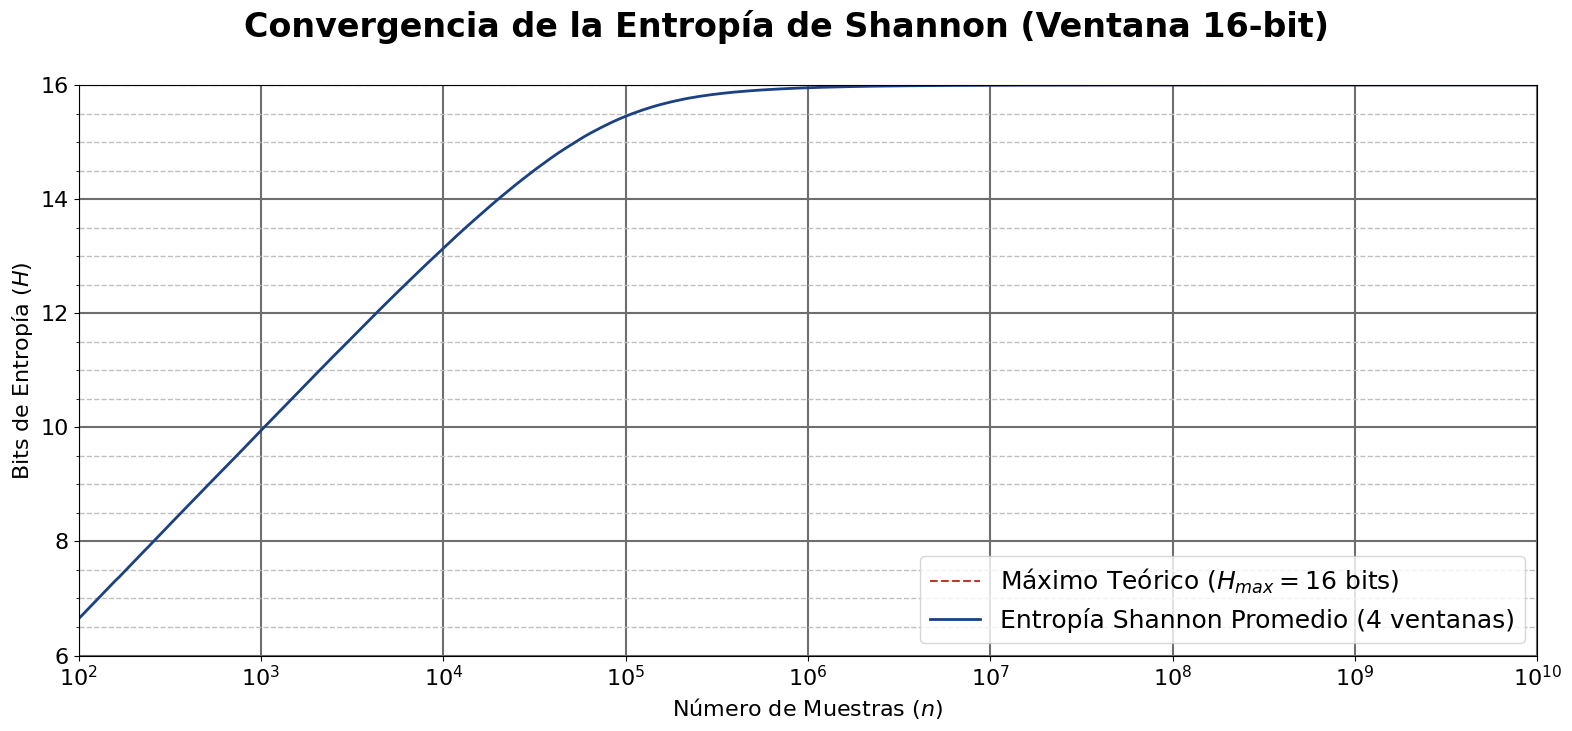

In [805]:
n_points  = [x for x, _ in chi2_log]
H_shannon = [y for _, y in entropy_log]

fig, ax = plt.subplots(figsize=FIGSIZE)

# 1. Ejes
ax.set_xscale('log', base=LOG_FACTOR)
ax.set_xlim(n_points[0], n_points[-1])

ax.set_ylim(6, 16)

ax.set_xlabel('Número de Muestras ($n$)')
ax.set_ylabel('Bits de Entropía ($H$)')

# 2. Ticks
min_pow = int(np.floor(np.log10(n_points[0])))
max_pow = int(np.ceil(np.log10(n_points[-1])))
pow_range = range(min_pow, max_pow + 1)

ax.set_xticks([10**i for i in pow_range])
ax.set_xticklabels([fr'$10^{{{i}}}$' for i in pow_range])

ax.minorticks_on()
ax.xaxis.set_minor_formatter(plt.NullFormatter())

# 3. Rejilla
ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

# 4. Títulos
fig.suptitle('Convergencia de la Entropía de Shannon (Ventana 16-bit)', fontweight='bold')

# 5. Elementos principales
ax.axhline(16.0, color=COLOR_RED, linestyle='--', linewidth=1.5,
           label='Máximo Teórico ($H_{max} = 16$ bits)')
ax.plot(n_points, H_shannon, label='Entropía Shannon Promedio (4 ventanas)',
        color=COLOR_BLUE, linewidth=2)

ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

## 2. Test de Avalancha

Análisis Sensibilidad de entrada/salida (Efecto Avalancha). Objetivo: cambio de ~50% bits salida ante cambio de 1 bit entrada.

### 2.1 Extracción de Datos


Generación de métricas de avalancha: cambios en salida vs flips de 1 bit en $S, X, Y$.

In [779]:
AVALANCHE_SAMPLES = 1_000_000_000
AVALANCHE_SEED = 0xDEADBEEFCAFEBABE

avalanche_output_file = Path("logs/avalanche_64b_output.txt")
avalanche_output_file.parent.mkdir(parents=True, exist_ok=True)

cmd = ["./zig-out/bin/avalanche_64b", str(AVALANCHE_SAMPLES), str(AVALANCHE_SEED), HASH_FUNCTION]
print(" ".join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True, check=True)
data_avalanche = result.stdout
avalanche_output_file.write_text(data_avalanche)

./zig-out/bin/avalanche_64b 1000000000 16045690984503098046 custom_v1


129518

#### 2.1.1 Datos en bruto obtenidos

In [780]:
data_avalanche.strip().splitlines()[:16]

['000, 000000000000, 000000000000, 000000000000',
 '001, 000000000000, 000000000000, 000000000000',
 '002, 000000000000, 000000000000, 000000000000',
 '003, 000000000000, 000000000000, 000000000000',
 '004, 000000000000, 000000000000, 000000000000',
 '005, 000000000000, 000000000000, 000000000000',
 '006, 000000000000, 000000000001, 000000000000',
 '007, 000000000001, 000000000000, 000000000000',
 '008, 000000000012, 000000000009, 000000000015',
 '009, 000000000085, 000000000092, 000000000099',
 '010, 000000000554, 000000000524, 000000000520',
 '011, 000000002508, 000000002479, 000000002567',
 '012, 000000011400, 000000011558, 000000011303',
 '013, 000000045645, 000000045458, 000000045781',
 '014, 000000165423, 000000165916, 000000165653',
 '015, 000000553583, 000000553802, 000000553258']

In [781]:
data_avalanche.strip().splitlines()[66:70]

['001: 031999853608, 031999954606, 032000148009 | S[499983674,500003814,500018791,500005416,499973391,500006826,500011298,500023358,499984207,499975010,500034325,500026106,500002603,499987229,499999567,499979009,499988404,499983779,499999231,499991571,499992314,499993171,500012203,499973559,499987726,499981307,500002685,500012190,500004716,499969124,500016028,500011573,499994741,500019599,500009512,499978424,500006182,499990993,500022378,500024780,500009502,500006499,500022963,499988809,499986607,499982703,499969271,499984591,499986572,499986237,499976491,499961968,499979496,499971862,500026207,500007409,499990923,500008248,500015044,499994786,500009459,499973012,500021104,500013031] X[500013389,500015876,500001456,500006102,500005613,500010938,500003952,499995471,499996059,500027246,500011860,499997264,499983907,499996875,500010578,500007287,500002527,499995585,500015490,500000005,499988376,499995690,499986861,499992371,500013133,500005470,500018523,499992145,499999414,499999674,49997

### 2.2 Refinado de Datos

Procesamiento: Frecuencias Hamming ($f_h$) y media cambios/bit ($\mu$).

In [782]:
dist_regex = re.compile(r'(\d+),\s+(\d+),\s+(\d+),\s+(\d+)')
dist_data = dist_regex.findall(data_avalanche)

sac_regex = re.compile(r'(\d+):\s+(\d+),\s+(\d+),\s+(\d+)\s+\|\s+S\[(.*?)\]\s+X\[(.*?)\]\s+Y\[(.*?)\]')
sac_matches = sac_regex.findall(data_avalanche)

f_h_s = [int(r[1]) for r in dist_data]
f_h_x = [int(r[2]) for r in dist_data]
f_h_y = [int(r[3]) for r in dist_data]
f_h_total = [s + x + y for s, x, y in zip(f_h_s, f_h_x, f_h_y)]

mu_flips_s = [int(r[1]) / AVALANCHE_SAMPLES for r in sac_matches]
mu_flips_x = [int(r[2]) / AVALANCHE_SAMPLES for r in sac_matches]
mu_flips_y = [int(r[3]) / AVALANCHE_SAMPLES for r in sac_matches]

# Matrices SAC (64x64): P(flip) por cada par (bit_entrada, bit_salida)
sac_matrix_s = np.array([list(map(int, r[4].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES
sac_matrix_x = np.array([list(map(int, r[5].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES
sac_matrix_y = np.array([list(map(int, r[6].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES

### 2.3 Visualización de Datos

#### 2.3.1 Análisis de la Distribución de Hamming y Efecto Avalancha

Comparación métricas observadas vs ideal teórico (Binomial, $\mu=32.0$).

In [783]:
mu_global = np.mean([mu_flips_s, mu_flips_x, mu_flips_y])

print(f"Promedio global de bits de salida girados ($\\mu$): {mu_global:.8f} (Ideal: 32.0)")
print(f"\tDesviación respecto al ideal: {abs(32.0 - mu_global):.8f}")
print("-" * 50)
print(f"Media S ($\\mu_s$): {np.mean(mu_flips_s):.8f}")
print(f"Media X ($\\mu_x$): {np.mean(mu_flips_x):.8f}")
print(f"Media Y ($\\mu_y$): {np.mean(mu_flips_y):.8f}")

Promedio global de bits de salida girados ($\mu$): 31.99999579 (Ideal: 32.0)
	Desviación respecto al ideal: 0.00000421
--------------------------------------------------
Media S ($\mu_s$): 32.00000728
Media X ($\mu_x$): 31.99998192
Media Y ($\mu_y$): 31.99999816


In [784]:
def plot_avalanche_effect(data, title):
    std_err = np.sqrt(64 * 0.5 * 0.5 / AVALANCHE_SAMPLES)
    margin = 3.0 * std_err
    ci_lower, ci_upper = 32.0 - margin, 32.0 + margin

    fig, ax = plt.subplots(figsize=FIGSIZE)

    # 1. Ejes
    ax.set_xlim(0, 64)
    y_min = 32.0 - margin * 3
    y_max = 32.0 + margin * 3
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('Posición del bit de entrada $j$ (0-63)')
    ax.set_ylabel('$\\mu$ bits girados')

    # 2. Ticks
    ax.set_xticks(np.arange(0, 65, 4))

    yticks = np.linspace(y_min, y_max, 7)
    ax.set_yticks(yticks)
    ax.set_yticklabels([f'{y:.5f}' for y in yticks])

    ax.minorticks_on()
    ax.xaxis.set_minor_locator(plt.MultipleLocator(1))

    # 3. Rejilla
    ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
    ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

    # 4. Títulos
    fig.suptitle(title, fontweight='bold')
    ax.set_title(f'Intervalo de confianza $3\\sigma \\approx 99.73\\%$ ($N=10^{{{int(np.log10(AVALANCHE_SAMPLES))}}}$)',
                 fontsize=SUBTITLE_FONT_SIZE, pad=10)

    # 5. Elementos principales
    ax.fill_between(range(65), ci_lower, ci_upper, color=COLOR_GREEN, alpha=0.2,
                    label='Zona de Aceptación (3$\\sigma$)')
    ax.axhline(y=32.0, color=COLOR_RED, linestyle='--', linewidth=1.5,
               label='Media Teórica ($\\mu=32.0$)')
    ax.stairs(list(data) + [data[-1]], baseline=None, color=COLOR_BLUE, linewidth=2,
                  zorder=2, label='Media Observada ($\\mu$)', alpha=0.8)

    ax.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

#### 2.3.2 Efecto Avalancha: Variando bits de $Seed$

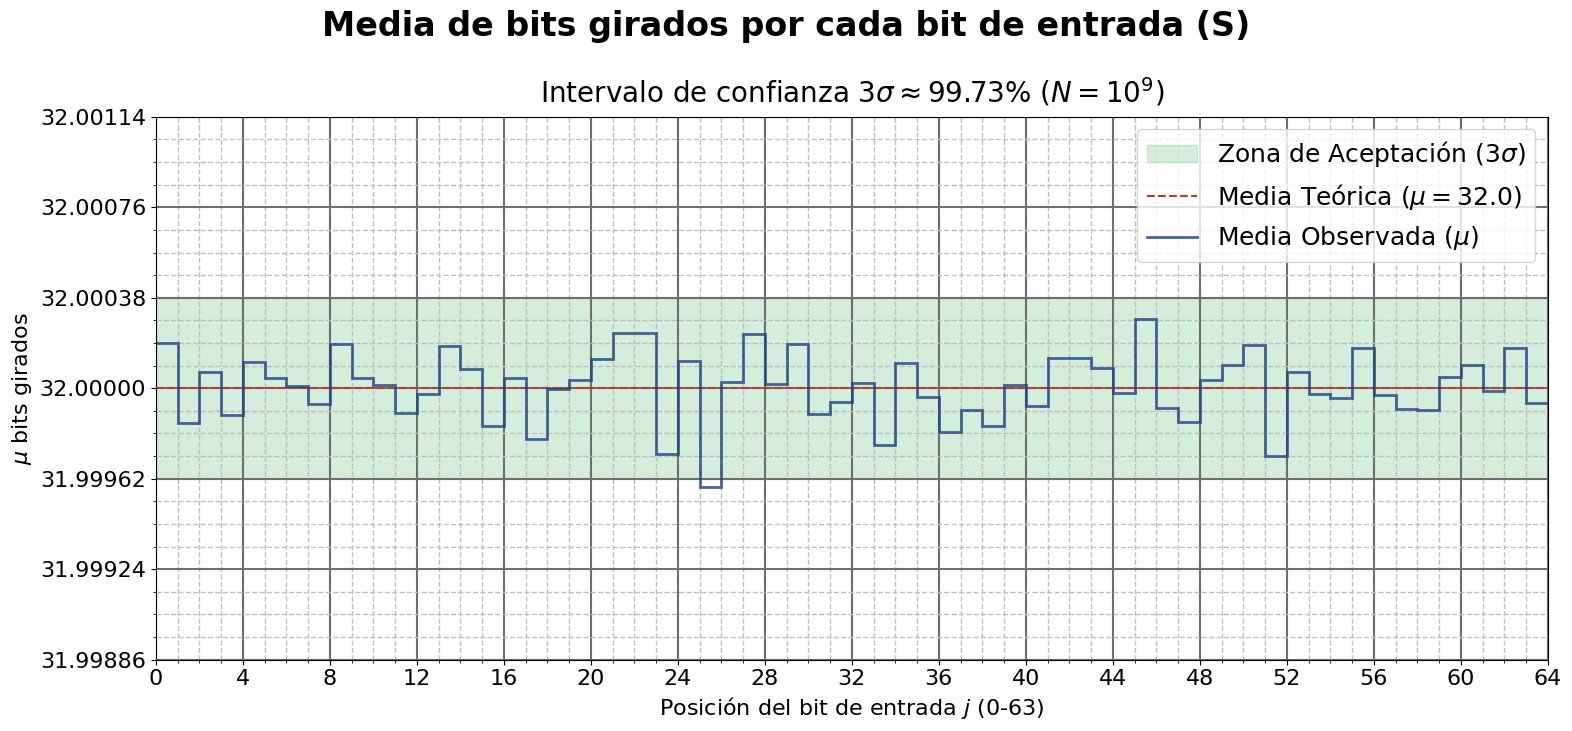

In [785]:
plot_avalanche_effect(mu_flips_s, "Media de bits girados por cada bit de entrada (S)")

#### 2.3.3 Efecto Avalancha: Variando bits de $X$


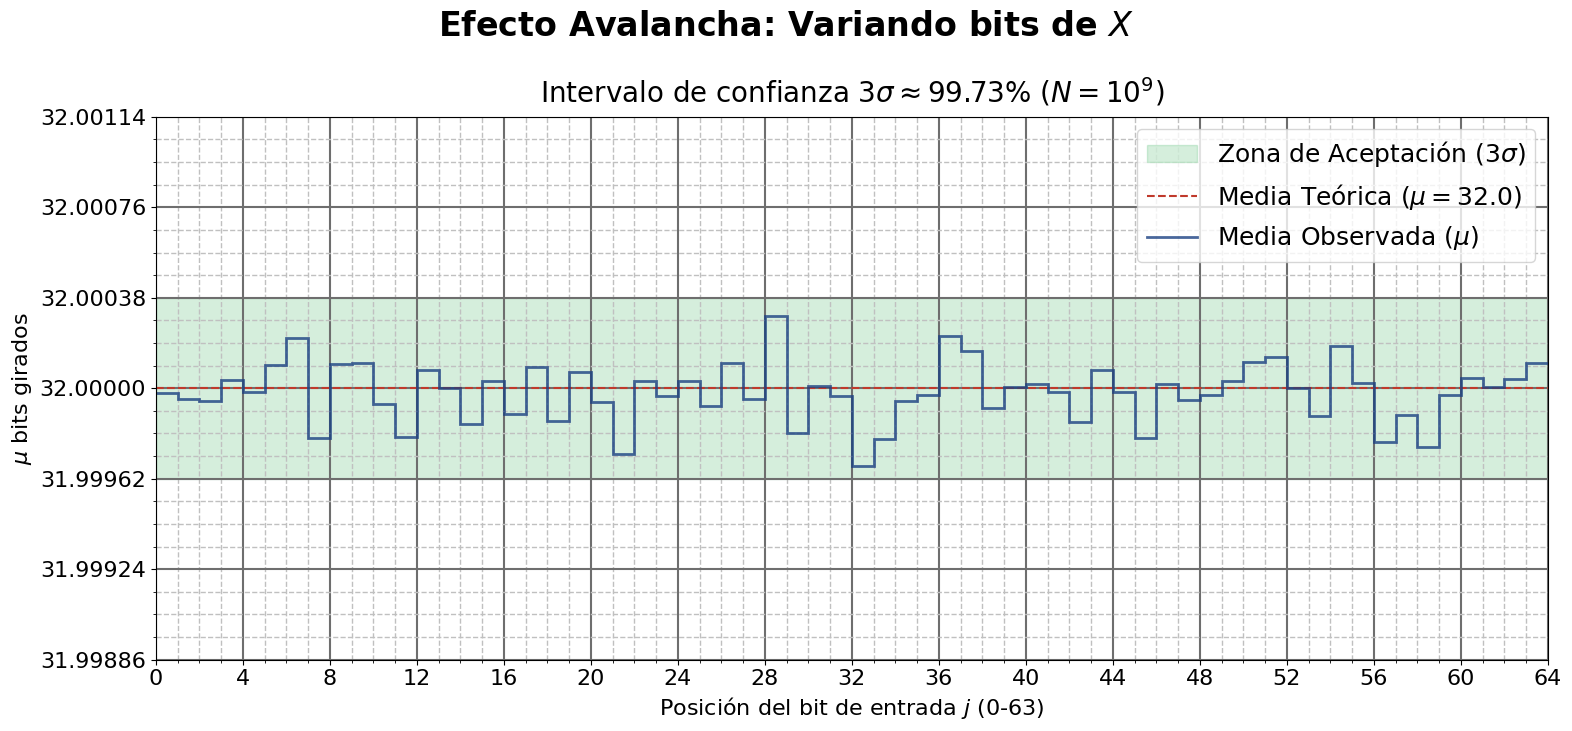

In [786]:
plot_avalanche_effect(mu_flips_x, 'Efecto Avalancha: Variando bits de $X$')

#### 2.3.4 Efecto Avalancha: Variando bits de $Y$

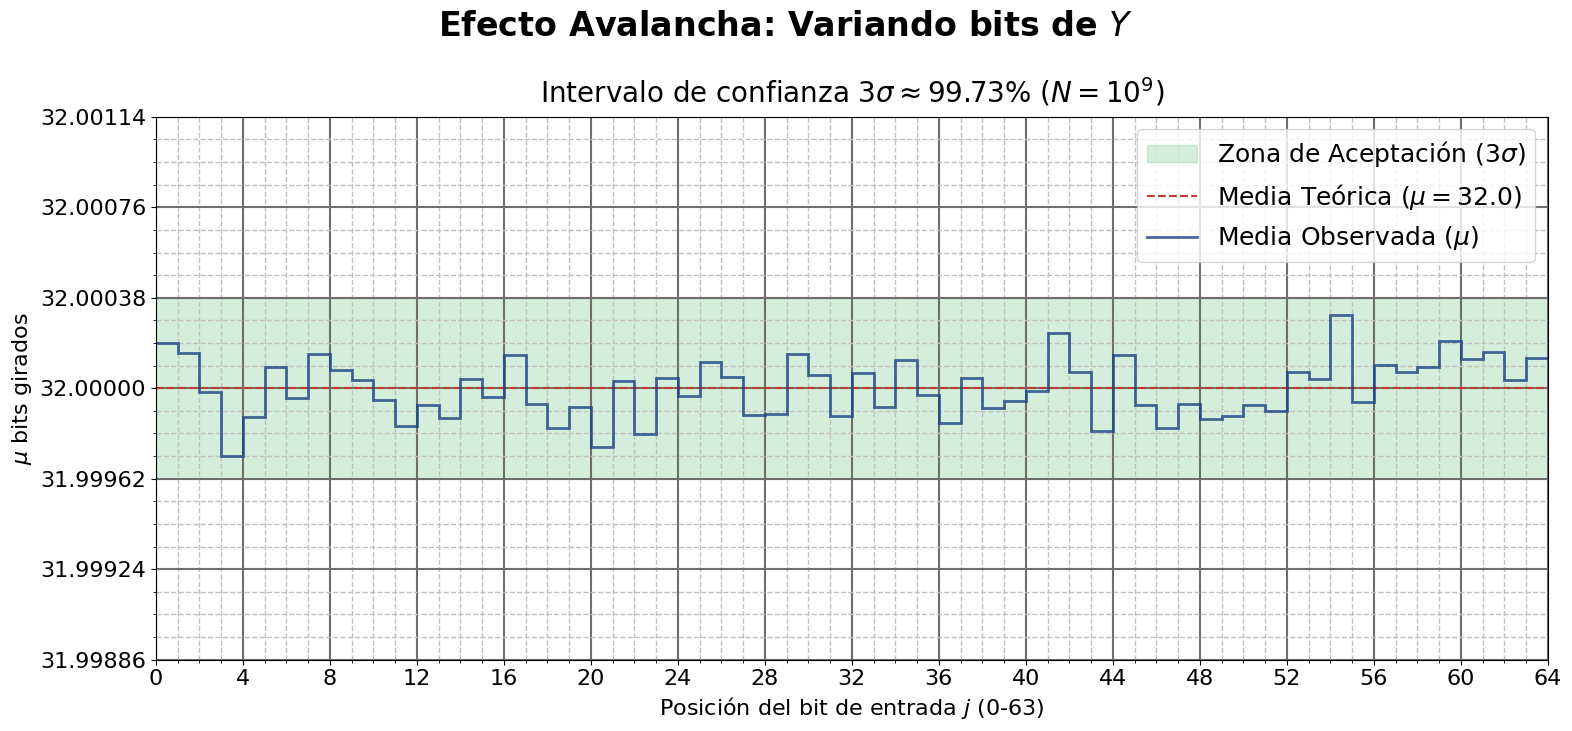

In [787]:
plot_avalanche_effect(mu_flips_y, 'Efecto Avalancha: Variando bits de $Y$')

#### 2.3.5 Distribución de Bits Cambiados (Distancia de Hamming $h$)

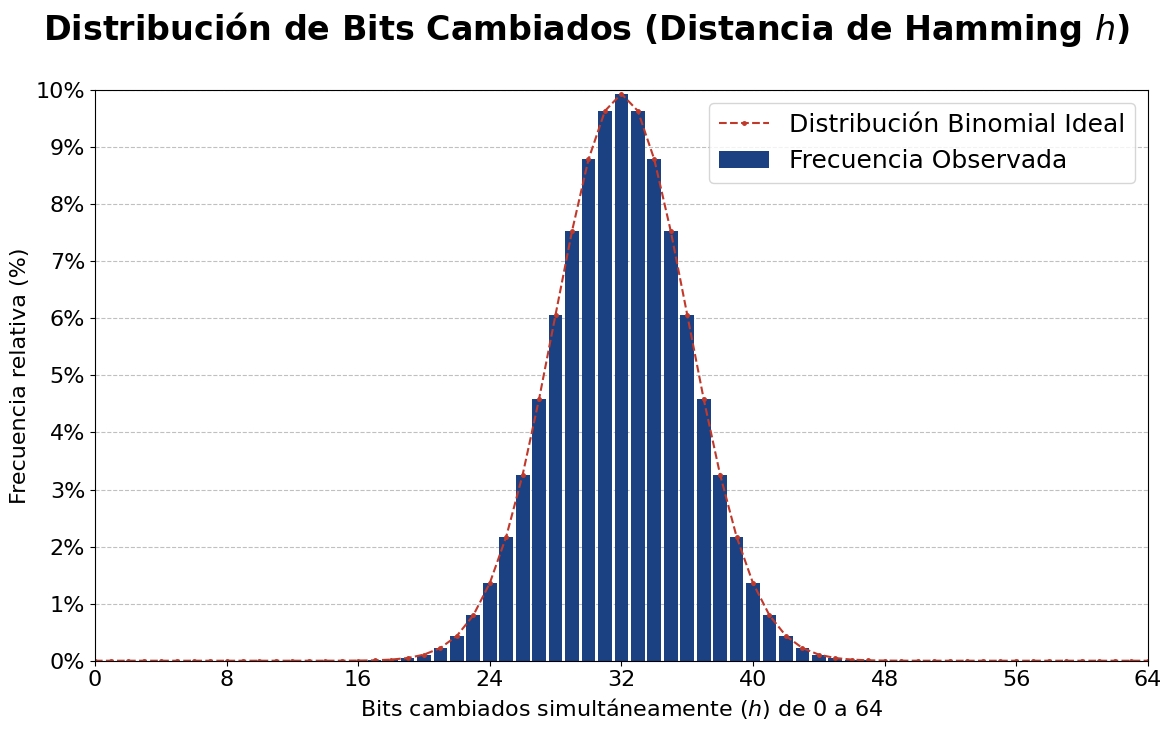

In [788]:
fig, ax = plt.subplots(figsize=(12, 7.5))

# 1. Ejes
h_vals = np.arange(len(f_h_total))
ax.set_xlabel('Bits cambiados simultáneamente ($h$) de 0 a 64')
ax.set_ylabel('Frecuencia relativa (%)')
ax.set_xlim(0, 64)
ax.set_ylim(0, 0.1)

# 2. Ticks
ax.set_xticks(range(0, 65, 8))
yticks_vals = np.linspace(0, 0.1, 11)
ax.set_yticks(yticks_vals)
ax.set_yticklabels([f'{y * 100:.0f}%' for y in yticks_vals])

# 3. Rejilla
ax.grid(axis='y', linestyle='--', color=GRAY)

# 4. Títulos
fig.suptitle('Distribución de Bits Cambiados (Distancia de Hamming $h$)', fontweight='bold')

# 5. Elementos principales
total_ensayos = 3 * 64 * AVALANCHE_SAMPLES
f_rel_total = np.array(f_h_total) / total_ensayos
dist_binomial = binom.pmf(h_vals, 64, 0.5)

ax.bar(h_vals, f_rel_total, width=5/6, color=COLOR_BLUE, label='Frecuencia Observada', zorder=2)
ax.plot(h_vals, dist_binomial, color=COLOR_RED, linestyle='--', marker='.',
        markersize=5, label='Distribución Binomial Ideal')

ax.legend()
plt.tight_layout()
plt.show()

#### 2.3.6 Análisis del Criterio de Avalancha Estricto (SAC)

Evaluación detallada de la independencia de bits.
*   **Izquierda:** Matriz $(i, j)$ donde varía S.
*   **Centro:** Matriz $(i, j)$ donde varía X.
*   **Derecha:** Matriz $(i, j)$ donde varía Y.

Cada celda representa la probabilidad de cambio en el bit de salida $j$ al invertir el bit de entrada $i$. El valor ideal es $0.5$ (verde). Desviaciones significativas (rojo) indican correlaciones no deseadas.

#### 2.3.7 Análisis Integral del SAC (S, X, Y)


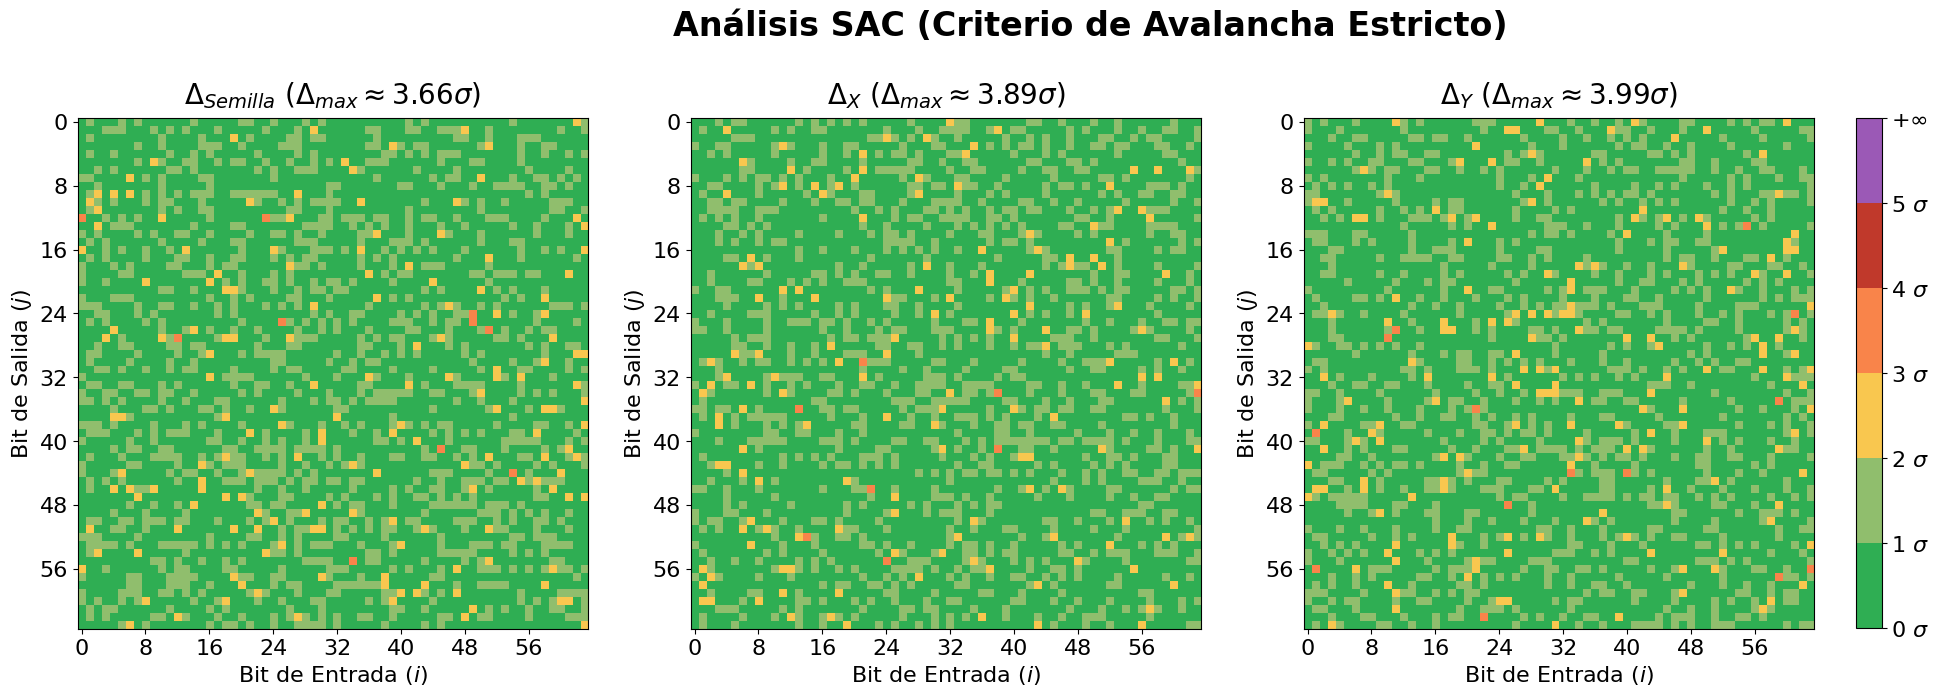

In [789]:
sac_configs = [
    (sac_matrix_s, '$\\Delta_{{Semilla}}$'),
    (sac_matrix_x, '$\\Delta_{{X}}$'),
    (sac_matrix_y, '$\\Delta_{{Y}}$')
]

fig, axes = plt.subplots(1, len(sac_configs), figsize=(27, 7.5))
axes = axes.flatten()

std_err_bit = 0.5 / np.sqrt(AVALANCHE_SAMPLES)
cmap = ListedColormap([COLOR_GREEN, COLOR_LIGHT_GREEN, COLOR_YELLOW, COLOR_ORANGE, COLOR_RED, COLOR_PURPLE])

for i, (matrix, title) in enumerate(sac_configs):
    ax = axes[i]
    z_scores = np.abs(matrix.T - 0.5) / std_err_bit
    z_mapped = np.digitize(z_scores, [1, 2, 3, 4, 5, 100])
    dev_max_sigma = np.max(z_scores)

    # 1. Ejes
    ax.set_xlim(-0.5, 63.5)
    ax.set_ylim(63.5, -0.5)
    ax.set_xlabel('Bit de Entrada ($i$)')
    ax.set_ylabel('Bit de Salida ($j$)')

    # 2. Ticks
    ax.set_xticks(np.arange(0, 64, 8))
    ax.set_yticks(np.arange(0, 64, 8))

    # 3. Títulos
    ax.set_title(f"{title} ($\\Delta_{{max}} \\approx {dev_max_sigma:.2f}\\sigma$)",
                 fontsize=SUBTITLE_FONT_SIZE, pad=10)

    # 4. Elementos principales
    im = ax.imshow(z_mapped, cmap=cmap, vmin=0, vmax=len(cmap.colors), aspect='equal', zorder=2)

# 5. Título y leyenda global
fig.suptitle('Análisis SAC (Criterio de Avalancha Estricto)', fontweight='bold')

cbar = fig.colorbar(im, ax=axes.tolist(), pad=0.02, shrink=883/1000)
cbar.set_ticks(np.arange(len(cbar.cmap.colors) + 1))
cbar.set_ticklabels(['0 $\\sigma$', '1 $\\sigma$', '2 $\\sigma$', '3 $\\sigma$', '4 $\\sigma$', '5 $\\sigma$', '$+\\infty$'])

plt.show()

## 3. Test de Patrones

Evaluación dual para detectar repeticiones no deseadas:
1. **Dominio Espacial:** Inspección visual directa para identificar artefactos geométricos.
2. **Dominio de Frecuencia (FFT):** Verificación matemática de la ausencia de periodicidad oculta.

### 3.1 Extracción de Datos

Generación de arrays binarios de secciones 2D (planos XY, XS, SY) de tamaño visualizable. 

(buscando visualizar el punto conflictivo $(0,0)$)

In [763]:
PATTERN_S = 0
PATTERN_X = -64
PATTERN_Y = -64
PATTERN_SIZE = 128
PATTERN_OUT_DIR = Path("logs")
PATTERN_OUT_DIR.mkdir(parents=True, exist_ok=True)

print("\nEjecutando test...")
cmd = ["./zig-out/bin/pattern_64b", str(PATTERN_S), str(PATTERN_X), str(PATTERN_Y), str(PATTERN_SIZE), str(PATTERN_OUT_DIR), HASH_FUNCTION]

subprocess.run(cmd, check=True)
print(' '.join(cmd))


Ejecutando test...
./zig-out/bin/pattern_64b 0 -64 -64 128 logs custom_v1


In [764]:
def plot_matrix_comparison(data_list, subplot_titles, main_title, axes_labels, cbar_label=None):
    fig, axes = plt.subplots(1, 3, figsize=(24, 6))

    for i, data in enumerate(data_list):
        ax = axes[i]

        # 1. Ejes
        ax.set_xlabel(axes_labels[i][0])
        ax.set_ylabel(axes_labels[i][1])

        # 2. Ticks
        size = data.shape[0]
        ticks = np.linspace(0, size, 9)
        
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)

        ax.set_xticklabels([f'{int(t)}' for t in ticks])
        ax.set_yticklabels([f'{int(t)}' for t in ticks])

        # 3. Títulos
        ax.set_title(subplot_titles[i], fontsize=SUBTITLE_FONT_SIZE)

        # 4. Elementos principales
        im = ax.imshow(data, cmap='gray', origin='lower')

    # 5. Título y leyenda global
    fig.suptitle(main_title, fontweight='bold')
    fig.colorbar(im, ax=axes.tolist(), shrink=0.950, aspect=10, pad=0.04, label=cbar_label)

    plt.show()

### 3.2 Inspección Visual (Dominio Espacial)

Visualización directa de los cortes generados (ficheros binarios `pattern_*.bin`).

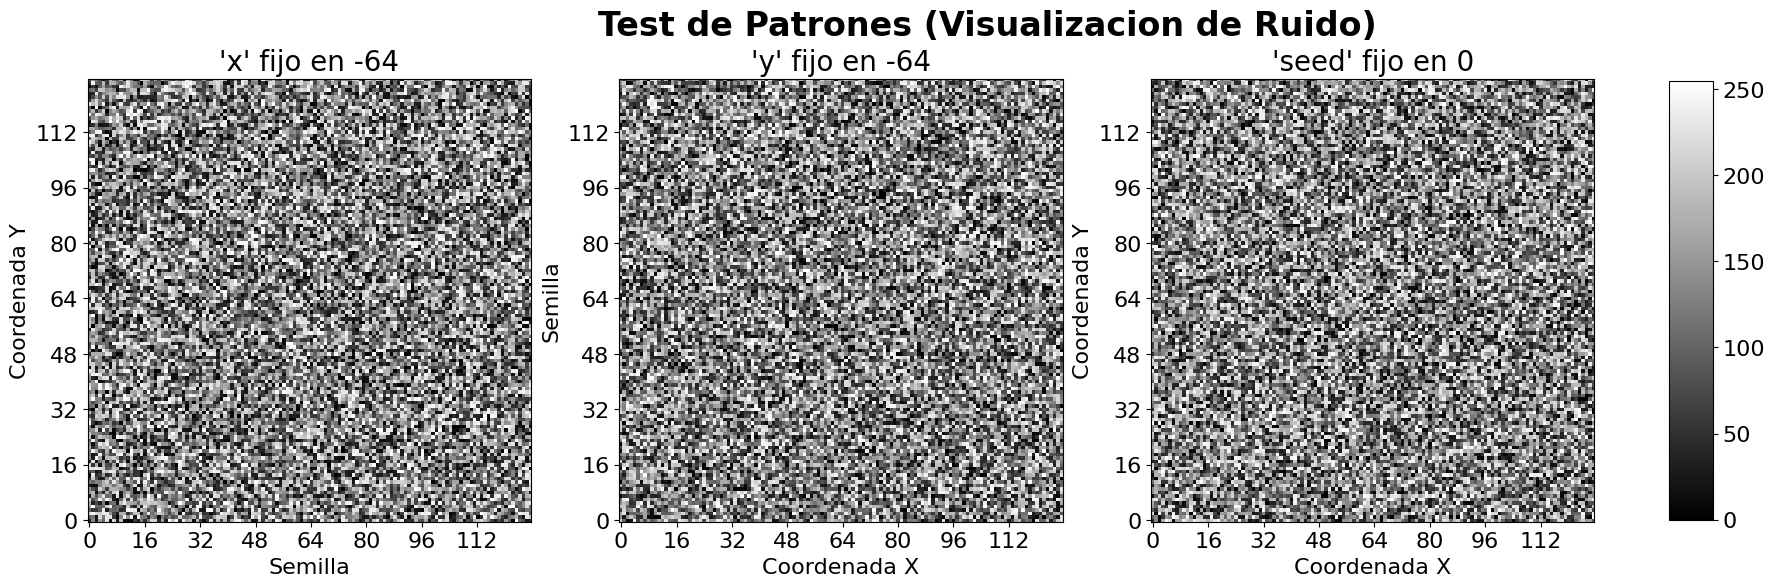

In [765]:
configs = [
    ('x', PATTERN_X, 'pattern_sy.bin', "Semilla", "Coordenada Y"),
    ('y', PATTERN_Y, 'pattern_xs.bin', "Coordenada X", "Semilla"),
    ('seed', PATTERN_S, 'pattern_xy.bin', "Coordenada X", "Coordenada Y")
]

def load_pattern_bin_u64(path, size):
    raw = np.fromfile(path, dtype=np.uint64)
    expected = size * size
    if raw.size != expected:
        raise ValueError(f"Tamaño invalido en {path}: {raw.size} elementos, esperado {expected}.")
    return raw.reshape((size, size))

pattern_data_u64 = [load_pattern_bin_u64(PATTERN_OUT_DIR / c[2], PATTERN_SIZE) for c in configs]

pattern_data_list = [(((arr >> 56)  ^ (arr >> 48) ^ (arr >> 40) ^ (arr >> 32) ^  (arr >> 24) ^ (arr >> 16) ^ (arr >> 8)) ^ (arr & 0xFF)).astype(np.uint8) for arr in pattern_data_u64]
subplot_titles = [f"'{c[0]}' fijo en {c[1]}" for c in configs]
spatial_labels = [(c[3], c[4]) for c in configs]

plot_matrix_comparison(pattern_data_list, subplot_titles,
                       "Test de Patrones (Visualizacion de Ruido)",
                       spatial_labels)

### 3.3 Análisis Espectral (FFT)

Transformada de Fourier 2D para analizar el dominio de la frecuencia.

**Objetivo:** Verificar la ausencia de periodicidad. Un buen ruido aleatorio (ruido blanco) debe mostrar una distribución de energía uniforme (espectro plano) sin picos dominantes o patrones geométricos claros (estrellas, líneas fuertes) que revelarían regularidades en el hash.

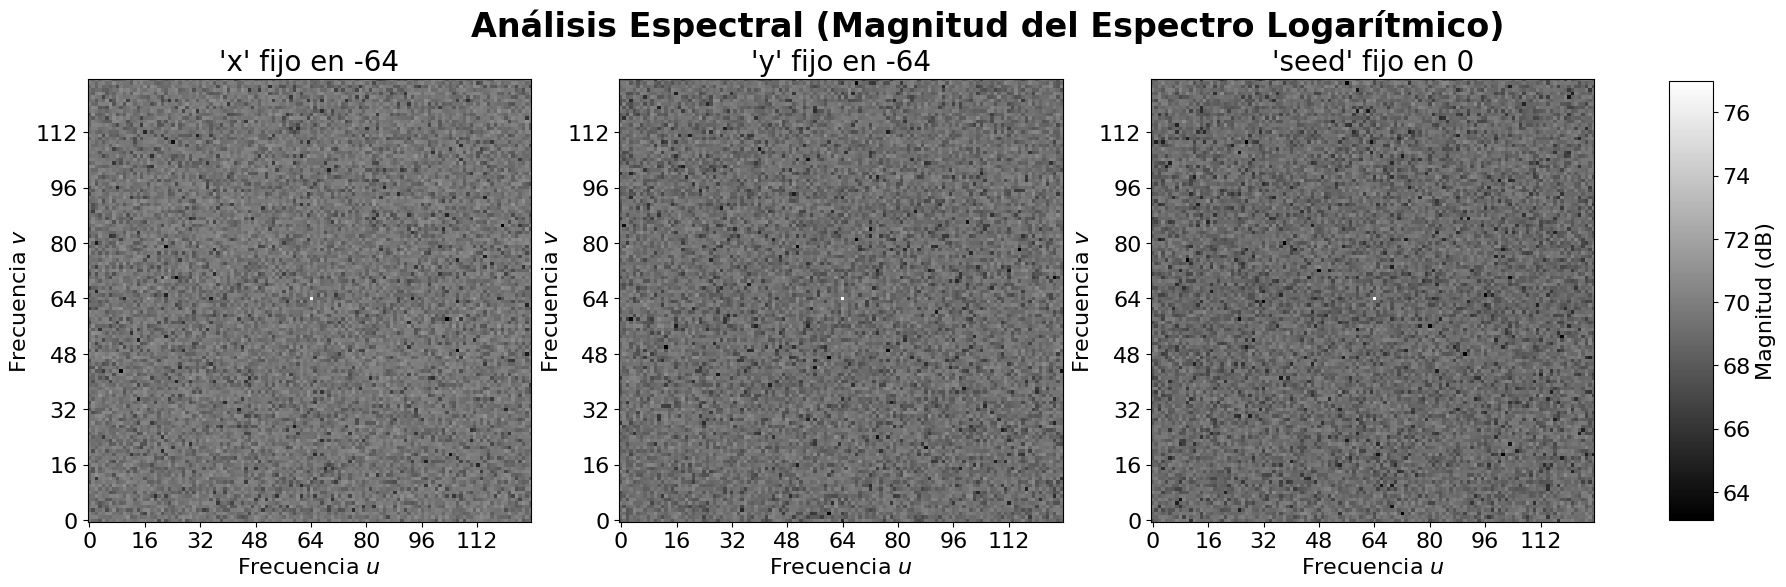

In [766]:
fft_data_list = []
for data in pattern_data_u64:
    f_shift = np.fft.fftshift(np.fft.fft2(data))
    f_shift = np.log2(np.abs(f_shift) + 1e-9)
    fft_data_list.append(f_shift)

fft_labels = [("Frecuencia $u$", "Frecuencia $v$")] * 3

plot_matrix_comparison(fft_data_list, subplot_titles,
                       "Análisis Espectral (Magnitud del Espectro Logarítmico)",
                       fft_labels,
                       cbar_label="Magnitud (dB)")

## 4. Análisis de colisiones

### 4.1 Extracción de Datos

In [794]:
SEEDS = 1_000_000_000
EXPLORATION_DEPTH = 1024
SEED_VAL = 0xDEADBEEFCAFEBABE

print("\nEjecutando test...")
cmd = ["./zig-out/bin/collisions_64b", str(SEEDS), str(EXPLORATION_DEPTH), str(SEED_VAL), HASH_FUNCTION]
result = subprocess.run(cmd, check=True, capture_output=True, text=True)
print(' '.join(cmd))

salida_zig = result.stdout


Ejecutando test...
./zig-out/bin/collisions_64b 1000000000 1024 16045690984503098046 custom_v1


#### 4.1.1 Datos en bruto obtenidos

In [795]:
for line in salida_zig.splitlines()[:10]:
    print(line.strip())

Byte 0 |   3999948191 |   4000121684
Byte 1 |   3999941214 |   3999921207
Byte 2 |   4000009773 |   4000167320
Byte 3 |   4000157060 |   3999956610
Byte 4 |   3999946487 |   4000209708
Byte 5 |   4000054795 |   4000302658
Byte 6 |   3999913314 |   4000142756
Byte 7 |   3999995573 |   3999937675


### 4.2 Refinado de datos

In [796]:
bytes_regex = re.compile(r'Byte\s+(\d+)\s*\|\s*(\d+)\s*\|\s*(\d+)')

bytes_matches = bytes_regex.findall(salida_zig)

total_comparisons = SEEDS * EXPLORATION_DEPTH

col_x = np.zeros(8)
col_y = np.zeros(8)

for w_idx, val_x, val_y in bytes_matches:
    idx = int(w_idx)
    col_x[idx] = int(val_x)
    col_y[idx] = int(val_y)

print(f"Total de comparaciones base (N): {total_comparisons}")

Total de comparaciones base (N): 1024000000000


### 4.2 Test de Colisiones en coordenadas colindantes

In [797]:
def plot_colisiones_espaciales(total_N, col_x, col_y, titulo_hash):
    bits = 8
    num_bloques = 64 // bits
    p = 1.0 / (2 ** bits)
    
    mu = total_N * p
    sigma = np.sqrt(total_N * p * (1 - p))
    
    z_x_real = (col_x - mu) / sigma
    z_y_real = (col_y - mu) / sigma
    
    valores_reales = [-27, -9, -3, 0, 3, 9, 27]
    alturas_visuales = [-3, -2, -1, 0, 1, 2, 3]
    
    z_x = np.interp(z_x_real, valores_reales, alturas_visuales)
    z_y = np.interp(z_y_real, valores_reales, alturas_visuales)
    
    x = np.arange(num_bloques)
    width = 1/3
    x_labels = [f'[{j*bits}-{(j+1)*bits-1}]' for j in range(num_bloques)]

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.set_ylim(-3, 3) 
    
    ax.set_yticks(alturas_visuales)
    ax.set_yticklabels([str(val) for val in valores_reales], fontsize=12)

    ax.fill_between([-1, num_bloques], -1, 1, color='lightgreen', alpha=0.2, 
                    label='Zona de Aceptación (3$\\sigma$)', zorder=1)
    ax.axhline(0, color='darkgray', linestyle='--', linewidth=1.5, zorder=2)
    
    ax.bar(x - width/2, z_x, width, color='coral', alpha=0.8, label='Horizontal (X)', zorder=3)
    ax.bar(x + width/2, z_y, width, color='steelblue', alpha=0.8, label='Vertical (Y)', zorder=3)

    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, fontsize=14)
    ax.set_xticks(x + 0.5, minor=True)
    ax.tick_params(axis='x', which='minor', bottom=False)

    ax.grid(which='major', axis='y', linestyle='-', linewidth=1, color='gray', alpha=0.5)
    ax.grid(which='minor', axis='x', linestyle='-', linewidth=1, color='gray', alpha=0.5)
    ax.grid(False, which='major', axis='x')

    ax.set_xlim(-0.5, num_bloques - 0.5)

    ax.set_title(f'Semilla fijada ({titulo_hash})', fontweight='bold', fontsize=14, pad=10)
    ax.set_ylabel('Z-Score ($\\sigma$)', fontweight='bold', fontsize=14)
    ax.legend(loc='upper right', fontsize=LEGEND_FONT_SIZE)

    plt.suptitle('Colisiones en coordenadas colindantes en slices de 8 bits (Límite ± 3$\\sigma$)', fontsize=16)

    plt.tight_layout()
    plt.show()

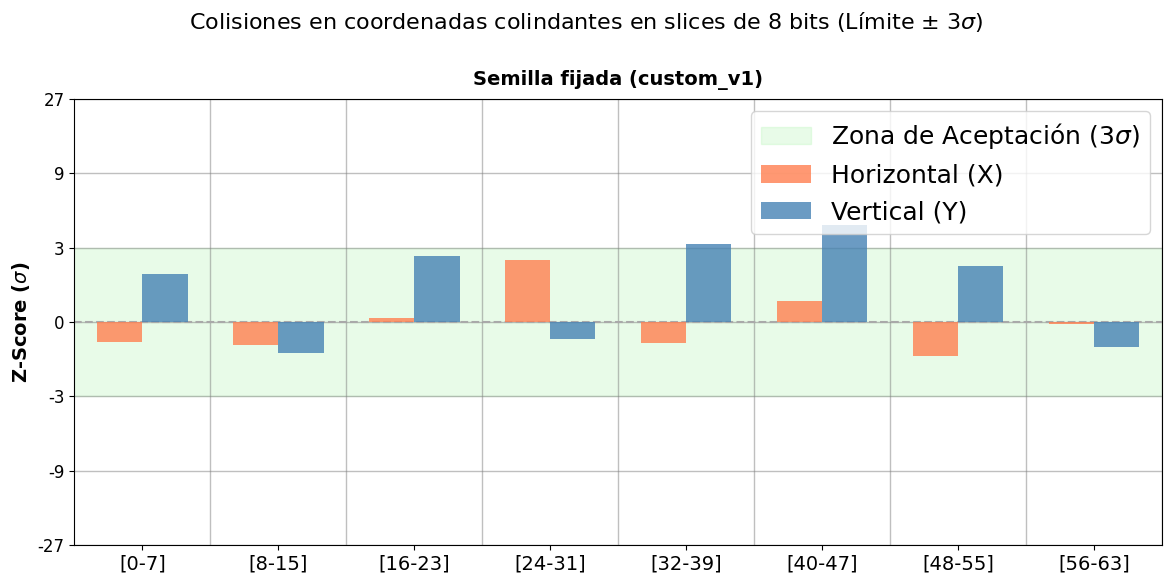

In [798]:
plot_colisiones_espaciales(total_comparisons, col_x, col_y, HASH_FUNCTION)

## 5. Test de Throughput (Monohilo)

Este apartado mide el coste de `hash(seed, x, y)` en ciclos por llamada.
El benchmark esta diseñado para reducir ruido de microbenchmarking:

- ejecuta una fase de warm-up antes de medir,
- mide lotes grandes y divide por el numero de hashes, evitando que el compilador optimize
- repite la medicion varias veces,

> Si ejecutas el benchmark en un procesador ARM, las mediciones de ciclos serán incorrectas en
> valores absolutos, pero sirven para comparar entre implementaciones a nivel local.
> Esto se debe a que es necesario el acceso al registro `PMCR_EL0`, al que hay que 
> solicitar acceso a invel de kernel. Puedes recalcular sabiendo la frecuencia del reloj 
> virtual y la frecuencia del reloj real

### 5.1 Extracción de Datos

Compilación y ejecución del benchmark C para obtención de métricas de rendimiento (ciclos/hash).

In [806]:
hashes = ["custom_v1", "custom_v2", "rapidhash"]
results_throughput = {}

UNROLL_FACTOR = 32
THROUGHPUT_REPS = 2**16 * 3
THROUGHPUT_BATCH = 2**14
THROUGHPUT_SEED = 0xDEADBEEFCAFEBABE

for hash_fn in hashes:
    throughput_output_file = Path(f"logs/throughput_output_64b_{hash_fn}.txt")
    throughput_output_file.parent.mkdir(parents=True, exist_ok=True)

    print(f"\nEjecutando test para {hash_fn}...")
    cmd = ["./zig-out/bin/throughput_64b",  str(THROUGHPUT_REPS), str(THROUGHPUT_BATCH), str(THROUGHPUT_SEED), hash_fn, str(UNROLL_FACTOR)]
    print(' '.join(cmd))

    result = subprocess.run(cmd, capture_output=True, text=True, check=True)
    data_throughput = result.stdout

    throughput_output_file.write_text(data_throughput)
    results_throughput[hash_fn] = data_throughput


Ejecutando test para custom_v1...
./zig-out/bin/throughput_64b 196608 16384 16045690984503098046 custom_v1 32

Ejecutando test para custom_v2...
./zig-out/bin/throughput_64b 196608 16384 16045690984503098046 custom_v2 32

Ejecutando test para rapidhash...
./zig-out/bin/throughput_64b 196608 16384 16045690984503098046 rapidhash 32


#### 5.1.1 Datos en bruto obtenidos

In [807]:
for hash_fn in hashes:
    print(f"Hash: {hash_fn}")
    print("Primeras líneas:")
    print("\t" + "\n\t".join(results_throughput[hash_fn].strip().splitlines()[:5]))
    print("")

Hash: custom_v1
Primeras líneas:
	REP    0 : 6.0190 cycles/hash
	REP    1 : 5.8530 cycles/hash
	REP    2 : 5.7681 cycles/hash
	REP    3 : 5.8352 cycles/hash
	REP    4 : 5.7388 cycles/hash

Hash: custom_v2
Primeras líneas:
	REP    0 : 5.8467 cycles/hash
	REP    1 : 5.6614 cycles/hash
	REP    2 : 5.4189 cycles/hash
	REP    3 : 5.6846 cycles/hash
	REP    4 : 5.5337 cycles/hash

Hash: rapidhash
Primeras líneas:
	REP    0 : 6.3459 cycles/hash
	REP    1 : 6.0093 cycles/hash
	REP    2 : 5.9341 cycles/hash
	REP    3 : 6.0298 cycles/hash
	REP    4 : 5.9519 cycles/hash



### 5.2 Refinado de Datos

Procesamiento de salida textual a estructuras numéricas (repeticiones, ciclos/hash, estadísticos).

In [808]:
REP_PATTERN = re.compile(r"REP\s+\d+\s+:\s+([0-9]+(?:\.[0-9]+)?)\s+cycles/hash")

def process_hash_statistics(values, sigma_threshold=6):
    mean_val = sum(values) / len(values)
    std_val = (sum((x - mean_val) ** 2 for x in values) / len(values)) ** 0.5
    
    limit = mean_val + (sigma_threshold * std_val)
    
    clean_values = [v for v in values if v <= limit]
    outliers_count = len(values) - len(clean_values)
    n_clean = len(clean_values)

    stats = {
        "cycles_per_rep": clean_values,
        "median": sorted(clean_values)[n_clean // 2],
        "min": min(clean_values),
        "max": max(clean_values),
        "mean": sum(clean_values) / n_clean,
        "threshold": limit
    }
    
    return stats, outliers_count

tp_stats = {}
for hash_fn in hashes:
    raw_results = results_throughput.get(hash_fn, "")
    
    cycles = [float(val) for val in REP_PATTERN.findall(raw_results)]
    
    sigma_threshold = 2
    stats, num_outliers = process_hash_statistics(cycles, sigma_threshold)
    tp_stats[hash_fn] = stats

    print(f"[!] {hash_fn}: {num_outliers:3} outliers eliminados (umbral > {stats['threshold']:.3f} cycles/hash | {sigma_threshold}σ)")

[!] custom_v1: 11876 outliers eliminados (umbral > 5.582 cycles/hash | 2σ)
[!] custom_v2: 8861 outliers eliminados (umbral > 5.150 cycles/hash | 2σ)
[!] rapidhash: 7254 outliers eliminados (umbral > 5.732 cycles/hash | 2σ)


### 5.3 Visualización de Datos

#### 5.3.1 Distribución de Ciclos por Hash

Histograma y boxplot para ver dispersión, outliers y concentración de las mediciones.

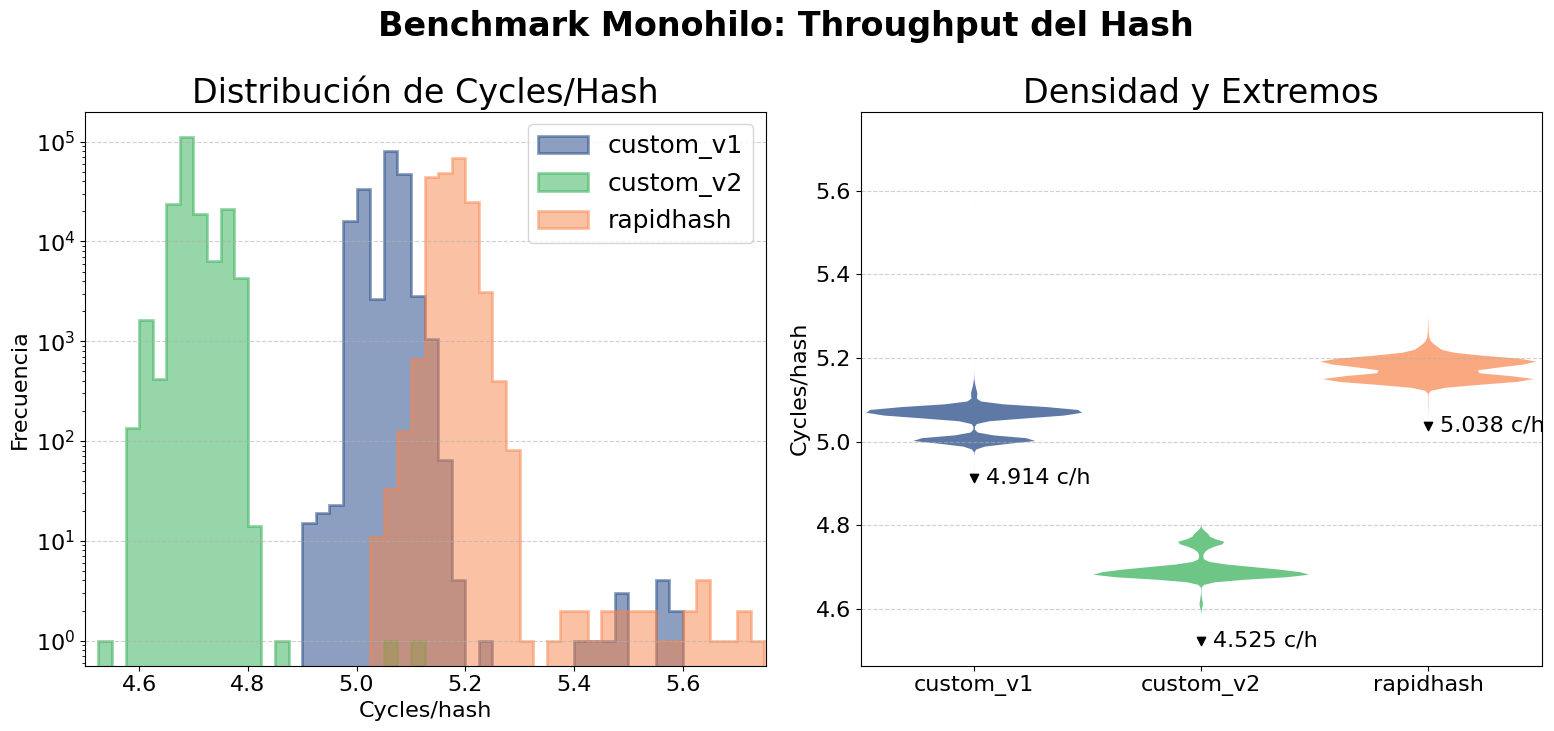

In [809]:
data_list = [tp_stats[hash_fn]["cycles_per_rep"] for hash_fn in hashes]

bins = np.arange(min(min(d) for d in data_list), max(max(d) for d in data_list) + 0.025, 0.025)

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
colors = [COLOR_BLUE, COLOR_GREEN, COLOR_ORANGE][:len(hashes)]

# --- 1. Histograma ---
for idx, d in enumerate(data_list):
    axes[0].hist(d, bins=bins, color=colors[idx], alpha=0.5, 
        histtype='stepfilled', edgecolor=colors[idx], linewidth=2, label=hashes[idx])

axes[0].set_title("Distribución de Cycles/Hash")
axes[0].set_xlabel("Cycles/hash")
axes[0].set_xlim(min(min(d) for d in data_list) - 0.025, max(max(d) for d in data_list) + 0.025)
axes[0].set_ylabel("Frecuencia")
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.6)
axes[0].set_yscale('log', base=10)

# --- 2. Gráfico de Violín ---
parts = axes[1].violinplot(data_list, showextrema=False, widths=0.95)

for idx, pc in enumerate(parts['bodies']):
    pc.set_facecolor(colors[idx])
    pc.set_alpha(0.7)

for idx, d in enumerate(data_list):
    min_c = min(d)
    axes[1].scatter(idx + 1, min_c, color='black', marker='v', zorder=3)
    axes[1].text(idx + 1 + 0.05, min_c, f"{min_c:.3f} c/h", color='black', va='center')

axes[1].set_title("Densidad y Extremos")
axes[1].set_ylabel("Cycles/hash")
axes[1].set_xticks(range(1, len(hashes) + 1))
axes[1].set_xticklabels(hashes)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)
axes[1].set_xlim(0.5, len(hashes) + 0.5)

fig.suptitle("Benchmark Monohilo: Throughput del Hash", fontweight='bold')
fig.tight_layout()
plt.show()

Recolectando datos de escalabilidad por factor de unroll...

Ejecutando unroll  1


	custom_v1    | Unroll  1 | Min Cycles/Hash: 11.063
	custom_v2    | Unroll  1 | Min Cycles/Hash: 14.005
	rapidhash    | Unroll  1 | Min Cycles/Hash: 12.065
Ejecutando unroll  2
	custom_v1    | Unroll  2 | Min Cycles/Hash: 5.990
	custom_v2    | Unroll  2 | Min Cycles/Hash: 7.005
	rapidhash    | Unroll  2 | Min Cycles/Hash: 6.497
Ejecutando unroll  3
	custom_v1    | Unroll  3 | Min Cycles/Hash: 4.609
	custom_v2    | Unroll  3 | Min Cycles/Hash: 4.817
	rapidhash    | Unroll  3 | Min Cycles/Hash: 4.684
Ejecutando unroll  4
	custom_v1    | Unroll  4 | Min Cycles/Hash: 4.573
	custom_v2    | Unroll  4 | Min Cycles/Hash: 4.005
	rapidhash    | Unroll  4 | Min Cycles/Hash: 4.214
Ejecutando unroll  8
	custom_v1    | Unroll  8 | Min Cycles/Hash: 4.409
	custom_v2    | Unroll  8 | Min Cycles/Hash: 3.310
	rapidhash    | Unroll  8 | Min Cycles/Hash: 3.975
Ejecutando unroll 16
	custom_v1    | Unroll 16 | Min Cycles/Hash: 4.416
	custom_v2    | Unroll 16 | Min Cycles/Hash: 4.158
	rapidhash    | Unroll 16

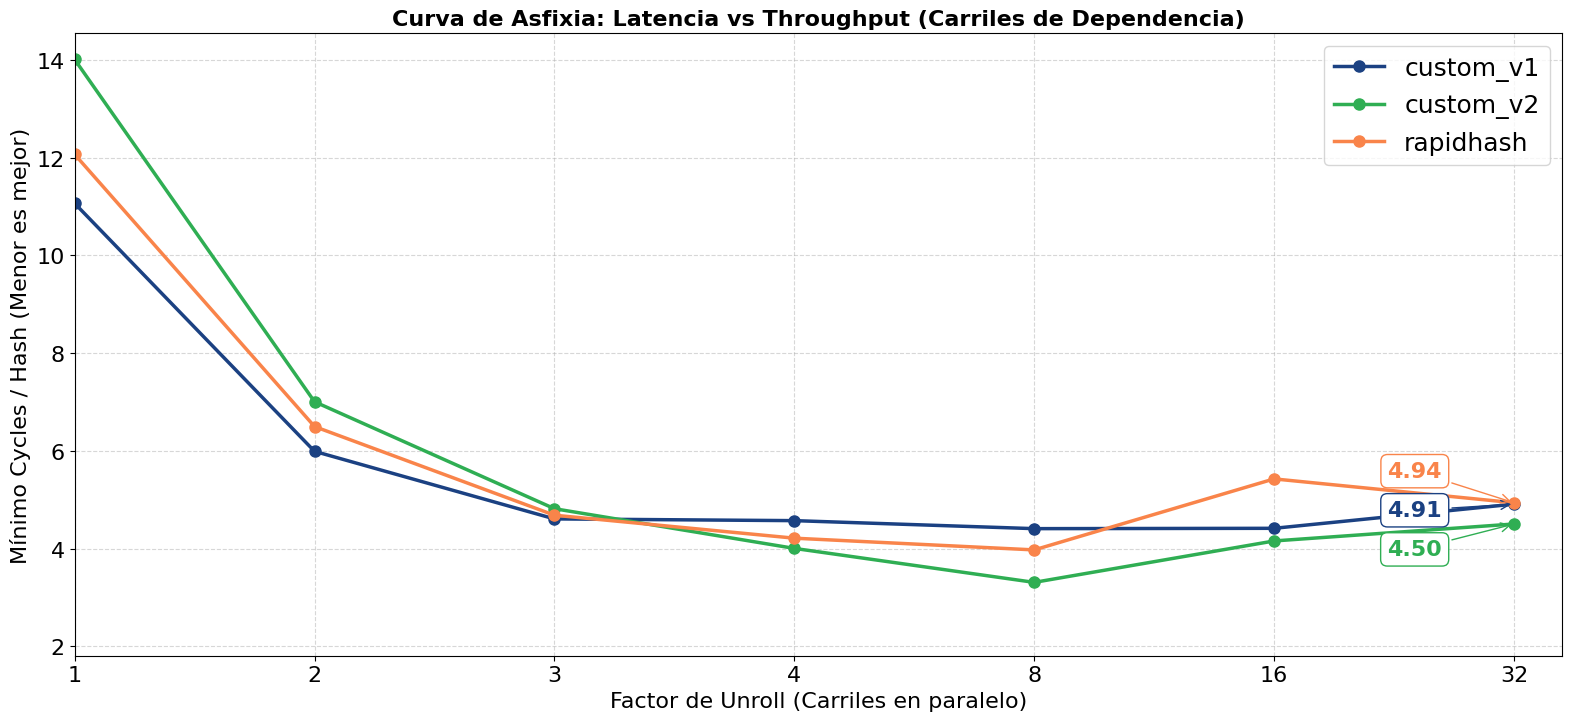

In [810]:
unroll_factors = [1, 2, 3, 4, 8, 16, 32]
min_cycles_per_hash = {h: [] for h in hashes}

print("Recolectando datos de escalabilidad por factor de unroll...\n")

for uf in unroll_factors:
    current_batch = THROUGHPUT_BATCH if THROUGHPUT_BATCH % uf == 0 else (THROUGHPUT_BATCH // uf) * uf
    print(f"Ejecutando unroll {uf:2d}")
    for hash_fn in hashes:
        cmd = [
            "./zig-out/bin/throughput_64b",  
            str(THROUGHPUT_REPS), 
            str(current_batch), 
            str(THROUGHPUT_SEED), 
            hash_fn, 
            str(uf)
        ]
        
        result = subprocess.run(cmd, capture_output=True, text=True, check=True)
        
        cycles = [float(val) for val in REP_PATTERN.findall(result.stdout)]
        
        min_cycle = min(cycles)
        min_cycles_per_hash[hash_fn].append(min_cycle)
        print(f"\t{hash_fn:12s} | Unroll {uf:2d} | Min Cycles/Hash: {min_cycle:.3f}")

fig, ax = plt.subplots(figsize=FIGSIZE)

colors = [COLOR_BLUE, COLOR_GREEN, COLOR_ORANGE]
x_indices = range(len(unroll_factors))
global_min = min([min(min_cycles_per_hash[h]) for h in hashes])

# 1. Primera pasada: Dibujar las líneas y guardar los puntos finales
final_points = []

for idx, hash_fn in enumerate(hashes):
    y_values = min_cycles_per_hash[hash_fn]
    
    # Dibujamos la línea de la gráfica
    ax.plot(x_indices, y_values, 
            marker='o', linestyle='-', linewidth=2.5, markersize=8,
            color=colors[idx], label=hash_fn)
    
    # Guardamos el punto final para procesarlo luego
    final_points.append({
        'hash': hash_fn,
        'y': y_values[-1],
        'color': colors[idx]
    })

# 2. Ordenar los puntos por su valor Y real (de menor a mayor)
final_points.sort(key=lambda item: item['y'])

# 3. Algoritmo de anti-colisión dinámico para las cajas de texto
min_spacing = 0.8  # Espacio vertical mínimo garantizado (ajusta este valor según la escala de tu eje Y)
text_y_positions = [item['y'] for item in final_points]

# Separar las etiquetas que estén demasiado juntas
for i in range(1, len(text_y_positions)):
    if text_y_positions[i] - text_y_positions[i-1] < min_spacing:
        text_y_positions[i] = text_y_positions[i-1] + min_spacing

# Centrar el grupo de etiquetas para que las flechas no se estiren solo hacia arriba
shift_down = (sum(text_y_positions) - sum(item['y'] for item in final_points)) / len(final_points)
text_y_positions = [y - shift_down for y in text_y_positions]

# 4. Segunda pasada: Dibujar las anotaciones con las posiciones seguras
final_x = x_indices[-1]

for i, point in enumerate(final_points):
    final_y = point['y']
    text_y = text_y_positions[i]
    
    ax.annotate(f"{final_y:.2f}", 
                xy=(final_x, final_y), 
                # Usamos la posición Y calculada en el algoritmo
                xytext=(final_x - 0.3, text_y),
                color=point['color'], va='center', ha='right', fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.3", facecolor='white', edgecolor=point['color'], alpha=1),
                arrowprops=dict(arrowstyle="->", color=point['color'], alpha=1))

# --- Configuración final de la gráfica ---
ax.set_title("Curva de Asfixia: Latencia vs Throughput (Carriles de Dependencia)", fontweight='bold', fontsize=16)
ax.set_xlabel("Factor de Unroll (Carriles en paralelo)", fontsize=LABEL_FONT_SIZE)
ax.set_ylabel("Mínimo Cycles / Hash (Menor es mejor)", fontsize=LABEL_FONT_SIZE)

ax.set_xticks(x_indices)
ax.set_xticklabels([str(x) for x in unroll_factors], fontsize=TICK_FONT_SIZE)

ax.set_ylim(bottom=max(0, global_min - 1.5))
# Ampliamos ligeramente el límite derecho para que quepan las cajas
ax.set_xlim(0, len(unroll_factors) - 0.8) 

ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=LEGEND_FONT_SIZE)

fig.tight_layout()
plt.show()